# Experimento 1: Clustering K-Means

Este notebook implementa el algoritmo K-Means sobre la matriz de características de trayectorias académicas. Se evalúa el comportamiento del modelo mediante métricas internas de validación de clustering.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

print("Entorno listo")

Entorno listo


In [2]:
ruta = Path("../data/processed/X_clustering.csv")

X = pd.read_csv(ruta)

X.head()

,periodos_registrados,promedio_global,creditos_totales,cursos_aprobados,cursos_desaprobados,cursos_previo_inicio,promedio_inicial,promedio_final,tendencia,tasa_aprobacion,variabilidad_nota
0,-0.487231,0.516412,-0.402032,-0.464573,-0.711080,-0.596566,0.147024,0.486179,0.433139,0.673603,-0.961629
1,-0.487231,-0.420977,-0.487768,0.028994,0.942910,1.321249,0.383717,-1.921609,-2.051139,-0.304771,1.363608
2,-0.487231,-0.366903,-0.487768,0.028994,0.777511,1.129467,0.265371,-1.921609,-2.009536,-0.222381,1.221827
3,-1.416016,-2.899670,-1.387992,-1.385899,0.446713,0.745904,-1.825423,-1.754733,-1.108143,-2.636562,1.369857
4,0.441553,0.189696,0.555349,0.950319,-0.545681,-0.596566,-0.629817,0.831851,1.050932,0.599907,-0.535305


In [3]:
X.shape

(244, 11)

In [4]:
resultados_kmeans = []

for k in range(2, 11):

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X)

    silhouette = silhouette_score(
        X,
        etiquetas
    )

    davies = davies_bouldin_score(
        X,
        etiquetas
    )

    resultados_kmeans.append({
        "k": k,
        "silhouette": silhouette,
        "davies_bouldin": davies
    })


resultados_kmeans = pd.DataFrame(resultados_kmeans)

resultados_kmeans

,k,silhouette,davies_bouldin
0,2,0.493255,0.898488
1,3,0.411377,0.915735
2,4,0.433560,1.072836
3,5,0.399566,1.191348
4,6,0.413721,1.023210
5,7,0.368558,0.966481
6,8,0.353395,1.127251
7,9,0.366114,1.006314
8,10,0.359533,1.011318


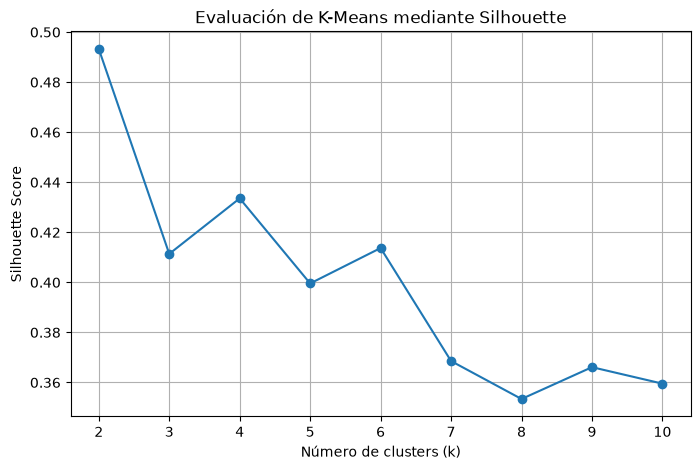

In [5]:
plt.figure(figsize=(8,5))

plt.plot(
    resultados_kmeans["k"],
    resultados_kmeans["silhouette"],
    marker="o"
)

plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette Score")

plt.title(
    "Evaluación de K-Means mediante Silhouette"
)

plt.grid()

plt.show()

In [6]:
mejor_k = (
    resultados_kmeans
    .sort_values(
        "silhouette",
        ascending=False
    )
    .iloc[0]["k"]
)

mejor_k

np.float64(2.0)

In [7]:
kmeans_final = KMeans(
    n_clusters=int(mejor_k),
    random_state=42,
    n_init=10
)

clusters = kmeans_final.fit_predict(X)

clusters

array([1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0,
       0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0,
       1, 1], dtype=int32)

In [8]:
resultado_kmeans = X.copy()

resultado_kmeans["cluster"] = clusters


resultado_kmeans.to_csv(
    "../results/kmeans/clusters_kmeans.csv",
    index=False,
    encoding="utf-8-sig"
)

In [9]:
pd.Series(clusters).value_counts()

1    172
0     72
Name: count, dtype: int64

In [10]:
silhouette_final = silhouette_score(
    X,
    clusters
)

davies_final = davies_bouldin_score(
    X,
    clusters
)

print("Silhouette:", silhouette_final)
print("Davies-Bouldin:", davies_final)

Silhouette: 0.4932552778604249
Davies-Bouldin: 0.8984879136738896


In [11]:
resultado_kmeans = pd.DataFrame({
    "modelo": ["K-Means"],
    "configuracion": [f"k={int(mejor_k)}"],
    "silhouette": [silhouette_final],
    "davies_bouldin": [davies_final]
})

resultado_kmeans

,modelo,configuracion,silhouette,davies_bouldin
0,K-Means,k=2,0.493255,0.898488


In [13]:
df_original = pd.read_csv(
    "../data/processed/trayectorias_academicas.csv"
)

In [14]:
resultado_clusters = df_original.copy()

resultado_clusters["cluster"] = clusters

In [15]:
resultado_clusters.groupby("cluster").mean(numeric_only=True)

,id_estudiante,periodos_registrados,promedio_global,creditos_totales,cursos_aprobados,cursos_desaprobados,cursos_previo_inicio,promedio_inicial,promedio_final,tendencia,tasa_aprobacion,variabilidad_nota
cluster,,,,,,,,,,,,
0,6.148804e+07,4.208333,9.847966,94.875000,26.208333,11.305556,8.861111,13.221065,3.282285,-9.938780,0.648875,5.664787
1,6.213927e+07,7.563953,14.589903,166.174419,55.872093,1.366279,0.703488,14.358346,14.961487,0.603141,0.978586,1.834606


In [16]:
caracterizacion_kmeans = (
    resultado_clusters
    .groupby("cluster")
    .mean(numeric_only=True)
)

caracterizacion_kmeans.to_csv(
    "../results/kmeans/caracterizacion_clusters.csv",
    encoding="utf-8-sig"
)

In [17]:
resultado_kmeans.to_csv(
    "../results/kmeans/evaluacion_kmeans.csv",
    index=False,
    encoding="utf-8-sig"
)